In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 

In [42]:
df = pd.read_csv(r"archive\UdemyCoursesDataset.csv")

In [43]:
df.head()

,course_id,course_title,is_paid,price,num_subscribers,num_reviews,num_lectures,level,content_duration,published_timestamp,subject
0,288942,#1 Piano Hand Coordination: Play 10th Ballad i...,True,35,3137,18,68,All Levels,1.5 hours,2014-09-18T05:07:05Z,Musical Instruments
1,1170074,#10 Hand Coordination - Transfer Chord Ballad ...,True,75,1593,1,41,Intermediate Level,1 hour,2017-04-12T19:06:34Z,Musical Instruments
2,1193886,#12 Hand Coordination: Let your Hands dance wi...,True,75,482,1,47,Intermediate Level,1.5 hours,2017-04-26T18:34:57Z,Musical Instruments
3,1116700,#4 Piano Hand Coordination: Fun Piano Runs in ...,True,75,850,3,43,Intermediate Level,1 hour,2017-02-21T23:48:18Z,Musical Instruments
4,1120410,#5 Piano Hand Coordination: Piano Runs in 2 ...,True,75,940,3,32,Intermediate Level,37 mins,2017-02-21T23:44:49Z,Musical Instruments


In [44]:
df.tail()

,course_id,course_title,is_paid,price,num_subscribers,num_reviews,num_lectures,level,content_duration,published_timestamp,subject
3677,328960,Your Own Site in 45 Min: The Complete Wordpres...,True,120,1566,29,36,All Levels,4 hours,2015-04-20T22:15:17Z,Web Development
3678,552700,Your Second Course on Piano: Two Handed Playing,True,70,1018,12,22,Beginner Level,5 hours,2015-10-26T20:04:21Z,Musical Instruments
3679,631754,Zend Framework 2: Learn the PHP framework ZF2 ...,True,40,723,130,37,All Levels,6.5 hours,2015-11-11T18:55:45Z,Web Development
3680,1225194,Zoho Books Gestion Financière d'Entreprise pas...,False,Free,229,0,33,All Levels,2 hours,2017-05-26T16:45:55Z,Business Finance
3681,964478,Zombie Apocalypse Photoshop Actions,True,50,12,1,15,All Levels,1.5 hours,2016-09-26T22:19:48Z,Graphic Design


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3682 entries, 0 to 3681
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   course_id            3682 non-null   int64 
 1   course_title         3682 non-null   object
 2   is_paid              3682 non-null   bool  
 3   price                3682 non-null   object
 4   num_subscribers      3682 non-null   int64 
 5   num_reviews          3682 non-null   int64 
 6   num_lectures         3682 non-null   int64 
 7   level                3682 non-null   object
 8   content_duration     3682 non-null   object
 9   published_timestamp  3682 non-null   object
 10  subject              3682 non-null   object
dtypes: bool(1), int64(4), object(6)
memory usage: 291.4+ KB


In [46]:
df.describe()

,course_id,num_subscribers,num_reviews,num_lectures
count,3.682000e+03,3682.000000,3682.000000,3682.000000
mean,6.766121e+05,3194.230310,156.093156,40.065182
std,3.436355e+05,9499.378361,934.957204,50.373299
min,8.324000e+03,0.000000,0.000000,0.000000
25%,4.078430e+05,110.250000,4.000000,15.000000
50%,6.885580e+05,911.500000,18.000000,25.000000
75%,9.617515e+05,2540.250000,67.000000,45.000000
max,1.282064e+06,268923.000000,27445.000000,779.000000


### **Data Cleaning**

In [47]:
df.isnull().sum()

course_id              0
course_title           0
is_paid                0
price                  0
num_subscribers        0
num_reviews            0
num_lectures           0
level                  0
content_duration       0
published_timestamp    0
subject                0
dtype: int64

In [48]:
df.dropna(inplace= True)

In [49]:
df.fillna(df.mode() , inplace= True)

In [50]:
df.duplicated().sum()

np.int64(6)

In [51]:
df.drop_duplicates(inplace= True)
df.duplicated().sum()

np.int64(0)

In [52]:
for x in df.index:
    if(df.loc[x , 'num_lectures'] == 0):
        df.drop(x , inplace= True)

In [53]:
df['course_id'].nunique()

3671

In [54]:
df.shape

(3671, 11)

### **Data Transformation**

In [55]:
df['published_timestamp'] = pd.to_datetime(df['published_timestamp'])
df['year'] = df['published_timestamp'].dt.year

In [56]:
df

,course_id,course_title,is_paid,price,num_subscribers,num_reviews,num_lectures,level,content_duration,published_timestamp,subject,year
0,288942,#1 Piano Hand Coordination: Play 10th Ballad i...,True,35,3137,18,68,All Levels,1.5 hours,2014-09-18 05:07:05+00:00,Musical Instruments,2014
1,1170074,#10 Hand Coordination - Transfer Chord Ballad ...,True,75,1593,1,41,Intermediate Level,1 hour,2017-04-12 19:06:34+00:00,Musical Instruments,2017
2,1193886,#12 Hand Coordination: Let your Hands dance wi...,True,75,482,1,47,Intermediate Level,1.5 hours,2017-04-26 18:34:57+00:00,Musical Instruments,2017
3,1116700,#4 Piano Hand Coordination: Fun Piano Runs in ...,True,75,850,3,43,Intermediate Level,1 hour,2017-02-21 23:48:18+00:00,Musical Instruments,2017
4,1120410,#5 Piano Hand Coordination: Piano Runs in 2 ...,True,75,940,3,32,Intermediate Level,37 mins,2017-02-21 23:44:49+00:00,Musical Instruments,2017
...,...,...,...,...,...,...,...,...,...,...,...,...
3677,328960,Your Own Site in 45 Min: The Complete Wordpres...,True,120,1566,29,36,All Levels,4 hours,2015-04-20 22:15:17+00:00,Web Development,2015
3678,552700,Your Second Course on Piano: Two Handed Playing,True,70,1018,12,22,Beginner Level,5 hours,2015-10-26 20:04:21+00:00,Musical Instruments,2015
3679,631754,Zend Framework 2: Learn the PHP framework ZF2 ...,True,40,723,130,37,All Levels,6.5 hours,2015-11-11 18:55:45+00:00,Web Development,2015
3680,1225194,Zoho Books Gestion Financière d'Entreprise pas...,False,Free,229,0,33,All Levels,2 hours,2017-05-26 16:45:55+00:00,Business Finance,2017


In [57]:
df['month'] = df['published_timestamp'].dt.month

In [58]:
df

,course_id,course_title,is_paid,price,num_subscribers,num_reviews,num_lectures,level,content_duration,published_timestamp,subject,year,month
0,288942,#1 Piano Hand Coordination: Play 10th Ballad i...,True,35,3137,18,68,All Levels,1.5 hours,2014-09-18 05:07:05+00:00,Musical Instruments,2014,9
1,1170074,#10 Hand Coordination - Transfer Chord Ballad ...,True,75,1593,1,41,Intermediate Level,1 hour,2017-04-12 19:06:34+00:00,Musical Instruments,2017,4
2,1193886,#12 Hand Coordination: Let your Hands dance wi...,True,75,482,1,47,Intermediate Level,1.5 hours,2017-04-26 18:34:57+00:00,Musical Instruments,2017,4
3,1116700,#4 Piano Hand Coordination: Fun Piano Runs in ...,True,75,850,3,43,Intermediate Level,1 hour,2017-02-21 23:48:18+00:00,Musical Instruments,2017,2
4,1120410,#5 Piano Hand Coordination: Piano Runs in 2 ...,True,75,940,3,32,Intermediate Level,37 mins,2017-02-21 23:44:49+00:00,Musical Instruments,2017,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3677,328960,Your Own Site in 45 Min: The Complete Wordpres...,True,120,1566,29,36,All Levels,4 hours,2015-04-20 22:15:17+00:00,Web Development,2015,4
3678,552700,Your Second Course on Piano: Two Handed Playing,True,70,1018,12,22,Beginner Level,5 hours,2015-10-26 20:04:21+00:00,Musical Instruments,2015,10
3679,631754,Zend Framework 2: Learn the PHP framework ZF2 ...,True,40,723,130,37,All Levels,6.5 hours,2015-11-11 18:55:45+00:00,Web Development,2015,11
3680,1225194,Zoho Books Gestion Financière d'Entreprise pas...,False,Free,229,0,33,All Levels,2 hours,2017-05-26 16:45:55+00:00,Business Finance,2017,5


In [59]:
df['hour'] = df['published_timestamp'].dt.hour

In [60]:
df

,course_id,course_title,is_paid,price,num_subscribers,num_reviews,num_lectures,level,content_duration,published_timestamp,subject,year,month,hour
0,288942,#1 Piano Hand Coordination: Play 10th Ballad i...,True,35,3137,18,68,All Levels,1.5 hours,2014-09-18 05:07:05+00:00,Musical Instruments,2014,9,5
1,1170074,#10 Hand Coordination - Transfer Chord Ballad ...,True,75,1593,1,41,Intermediate Level,1 hour,2017-04-12 19:06:34+00:00,Musical Instruments,2017,4,19
2,1193886,#12 Hand Coordination: Let your Hands dance wi...,True,75,482,1,47,Intermediate Level,1.5 hours,2017-04-26 18:34:57+00:00,Musical Instruments,2017,4,18
3,1116700,#4 Piano Hand Coordination: Fun Piano Runs in ...,True,75,850,3,43,Intermediate Level,1 hour,2017-02-21 23:48:18+00:00,Musical Instruments,2017,2,23
4,1120410,#5 Piano Hand Coordination: Piano Runs in 2 ...,True,75,940,3,32,Intermediate Level,37 mins,2017-02-21 23:44:49+00:00,Musical Instruments,2017,2,23
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3677,328960,Your Own Site in 45 Min: The Complete Wordpres...,True,120,1566,29,36,All Levels,4 hours,2015-04-20 22:15:17+00:00,Web Development,2015,4,22
3678,552700,Your Second Course on Piano: Two Handed Playing,True,70,1018,12,22,Beginner Level,5 hours,2015-10-26 20:04:21+00:00,Musical Instruments,2015,10,20
3679,631754,Zend Framework 2: Learn the PHP framework ZF2 ...,True,40,723,130,37,All Levels,6.5 hours,2015-11-11 18:55:45+00:00,Web Development,2015,11,18
3680,1225194,Zoho Books Gestion Financière d'Entreprise pas...,False,Free,229,0,33,All Levels,2 hours,2017-05-26 16:45:55+00:00,Business Finance,2017,5,16


### **EDA && Visualization**

<Axes: >

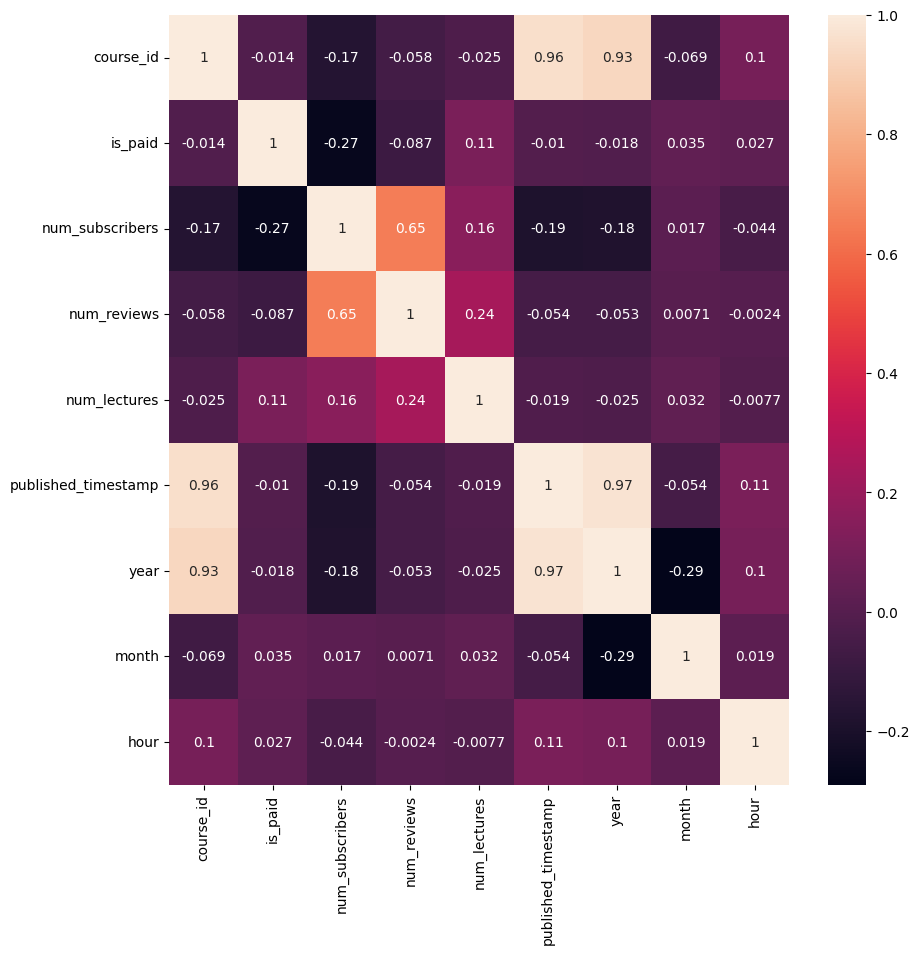

In [61]:
numerical_df = df.select_dtypes(exclude= np.object_)
plt.figure(figsize= (10,10))
sns.heatmap (numerical_df.corr() , annot= True)

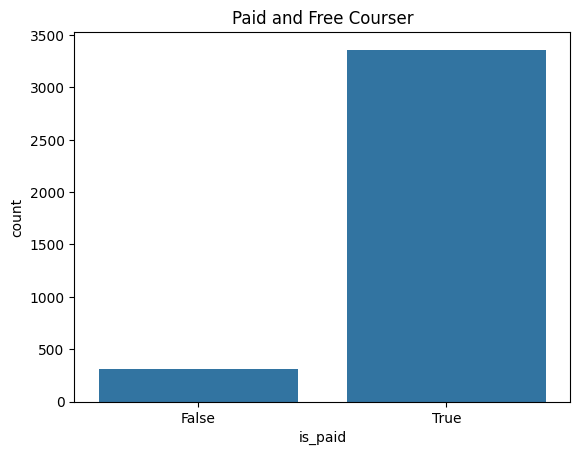

In [62]:
sns.countplot( x = 'is_paid' , data= df)
plt.title('Paid and Free Courser')
plt.show()

In [63]:
df['is_paid'].value_counts()

is_paid
True     3361
False     310
Name: count, dtype: int64

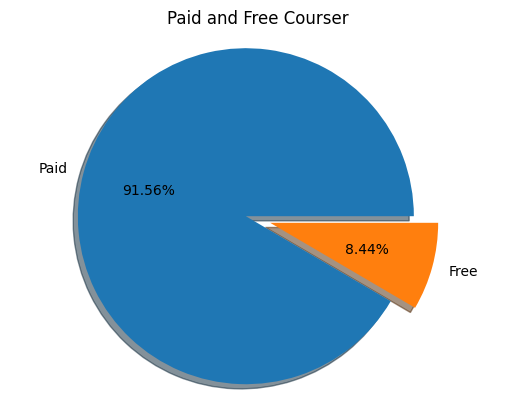

In [64]:
plt.pie(df['is_paid'].value_counts() , 
        labels = ('Paid','Free') , 
        autopct = '%1.2f%%' , 
        shadow = True , 
        explode = [0 , 0.15])
plt.title('Paid and Free Courser')
plt.axis('equal')
plt.show()

<Axes: title={'center': 'Avarge Demand (Free/Paid)'}, xlabel='is_paid', ylabel='num_subscribers'>

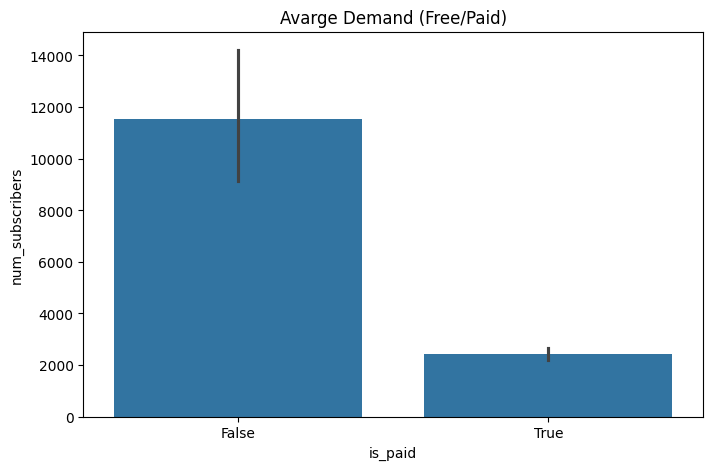

In [65]:
plt.figure(figsize= (8,5))
plt.title('Avarge Demand (Free/Paid)')
sns.barplot( x = 'is_paid' , y= 'num_subscribers' , data= df)

In [66]:
df['subject'].value_counts()

subject
Web Development        1199
Business Finance       1190
Musical Instruments     680
Graphic Design          602
Name: count, dtype: int64

<Axes: xlabel='subject', ylabel='count'>

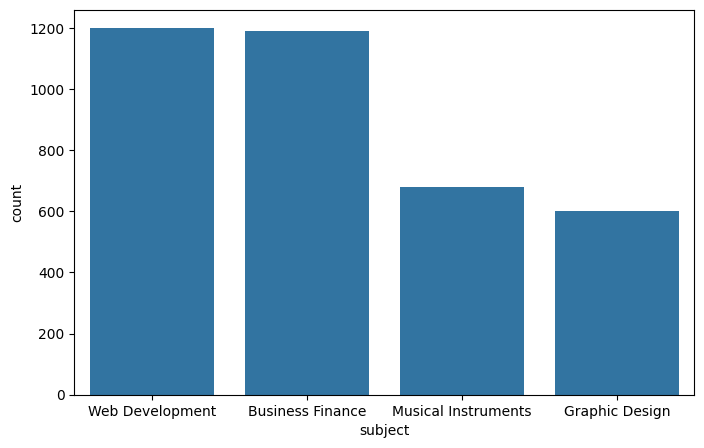

In [67]:
plt.figure(figsize= (8,5))
sns.countplot(data= df , x= 'subject' , order= df.subject.value_counts().index)

<Axes: title={'center': 'Avarge Demand (Free/Paid)'}, xlabel='is_paid', ylabel='num_subscribers'>

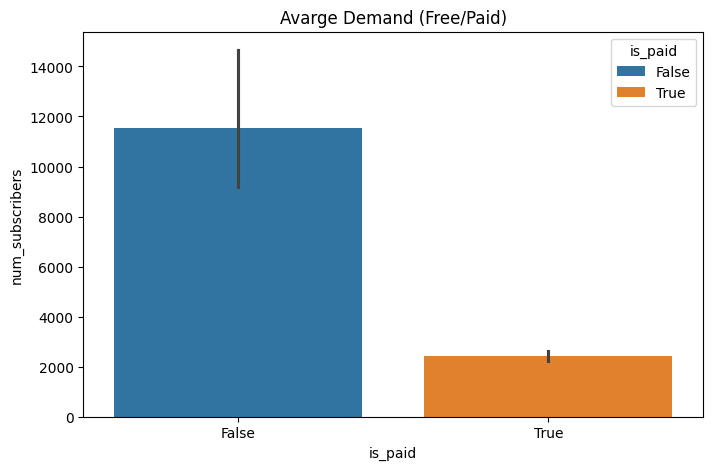

In [68]:
plt.figure(figsize= (8,5))
plt.title('Avarge Demand (Free/Paid)')
sns.barplot( x = 'is_paid' , y= 'num_subscribers' , hue= 'is_paid' , data= df)

<Axes: xlabel='level', ylabel='count'>

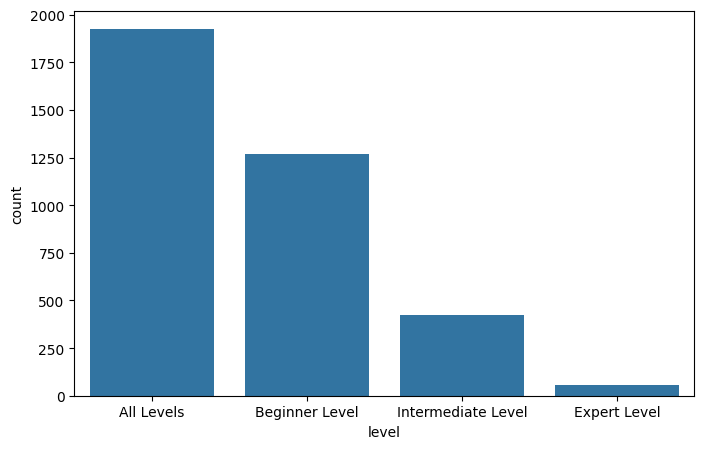

In [69]:
plt.figure(figsize= (8,5))
sns.countplot(data= df , x= 'level' , order= df.level.value_counts().index)

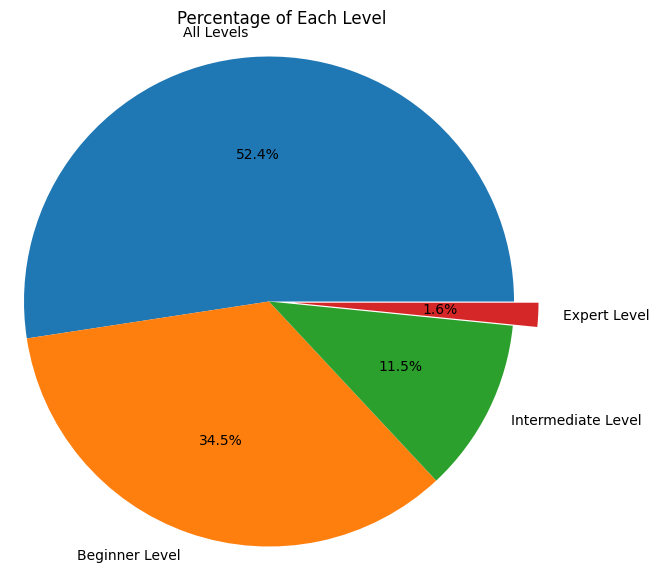

In [70]:
plt.figure(figsize=(7, 7))
plt.pie(
    df['level'].value_counts(),
    labels=['All Levels', 'Beginner Level', 'Intermediate Level', 'Expert Level'],
    autopct='%1.1f%%',
    explode=[0, 0, 0, 0.1]
)
plt.title('Percentage of Each Level')
plt.axis('equal')
plt.show()

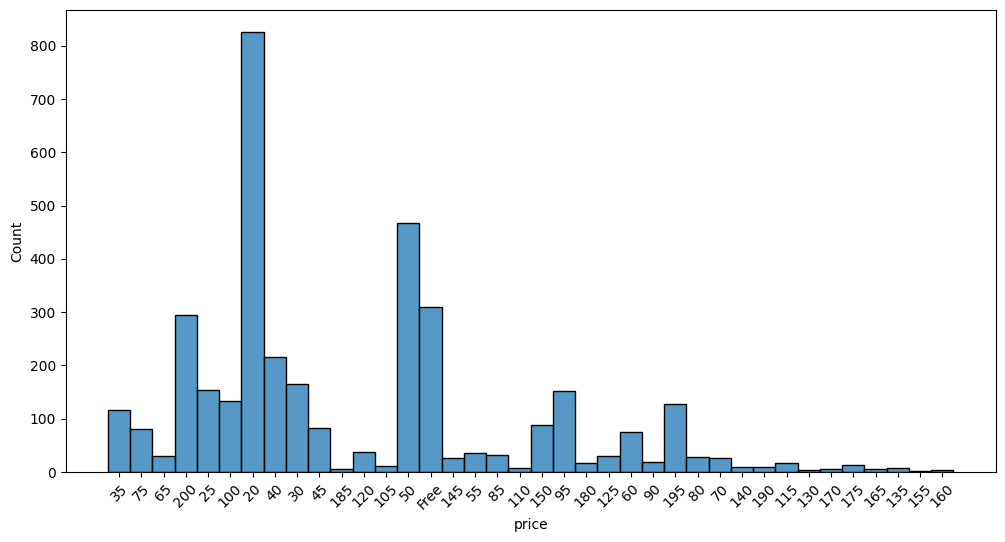

In [71]:
plt.figure(figsize=(12, 6))
sns.histplot(data=df , x='price' , bins= 40)
plt.xticks(rotation=45)
plt.show()

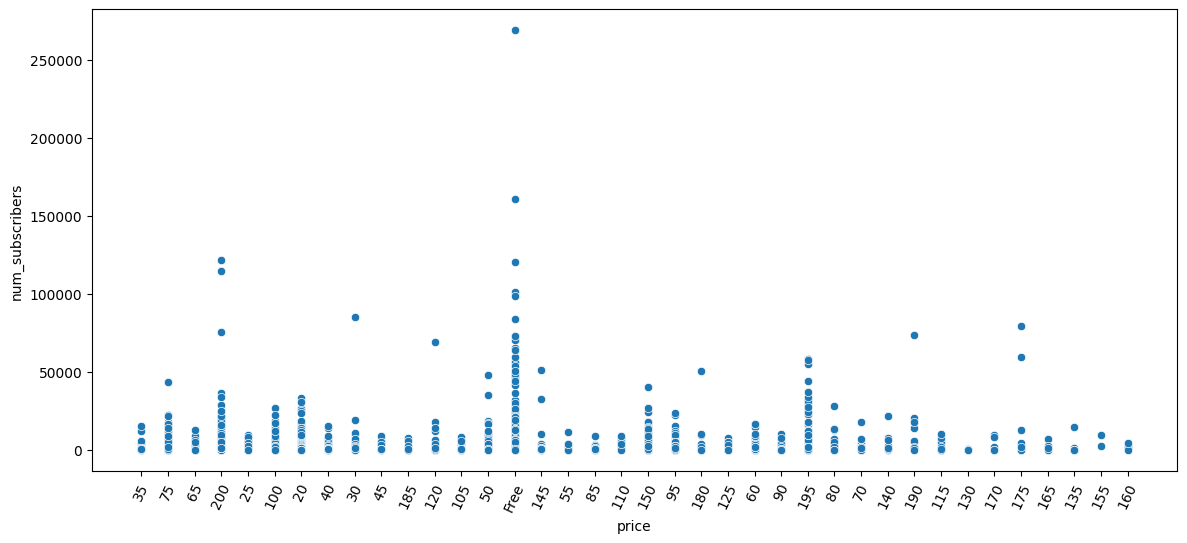

In [72]:
plt.figure(figsize=(14, 6))
sns.scatterplot( x= 'price' , y= 'num_subscribers' , data= df)
plt.xticks(rotation=65)
plt.show()

In [73]:
df['price_clean'] = df['price'].replace('Free', 0)
df['price_clean'] = pd.to_numeric(df['price_clean'])

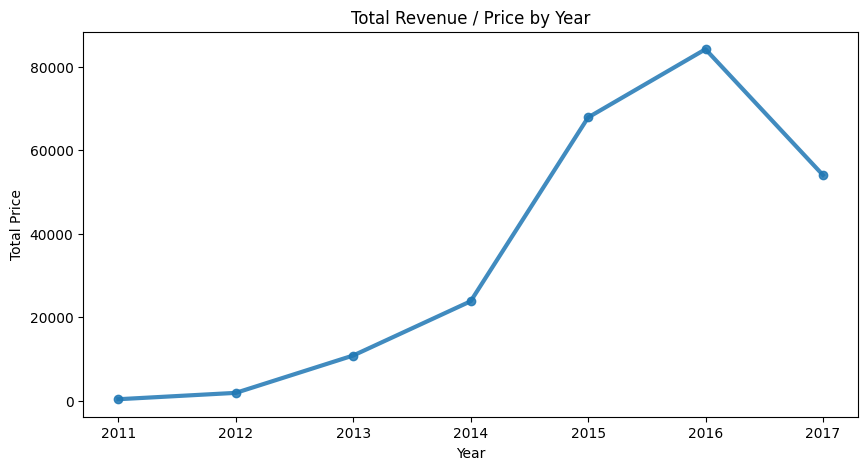

In [74]:
plt.figure(figsize=(10, 5))
plt.plot(
    df.groupby('year')['price_clean'].sum() ,
    ls='-',  
    marker='o',  
    lw=3,
    alpha=0.85,
    color='tab:blue',
)

plt.title('Total Revenue / Price by Year')
plt.xlabel('Year')
plt.ylabel('Total Price')
plt.show()

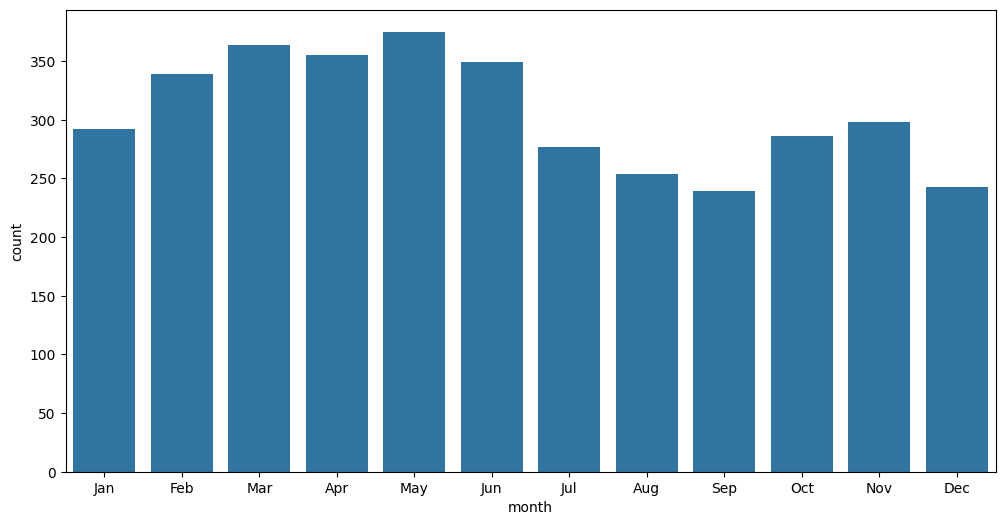

In [75]:
plt.figure(figsize=(12,6))
sns.countplot(data=df , x='month')
plt.xticks(range(0,12),
           ['Jan' , 'Feb' , 'Mar' , 'Apr' , 'May' ,
             'Jun' , 'Jul' , 'Aug' , 'Sep' , 'Oct' , 'Nov' , 'Dec'])
plt.show()


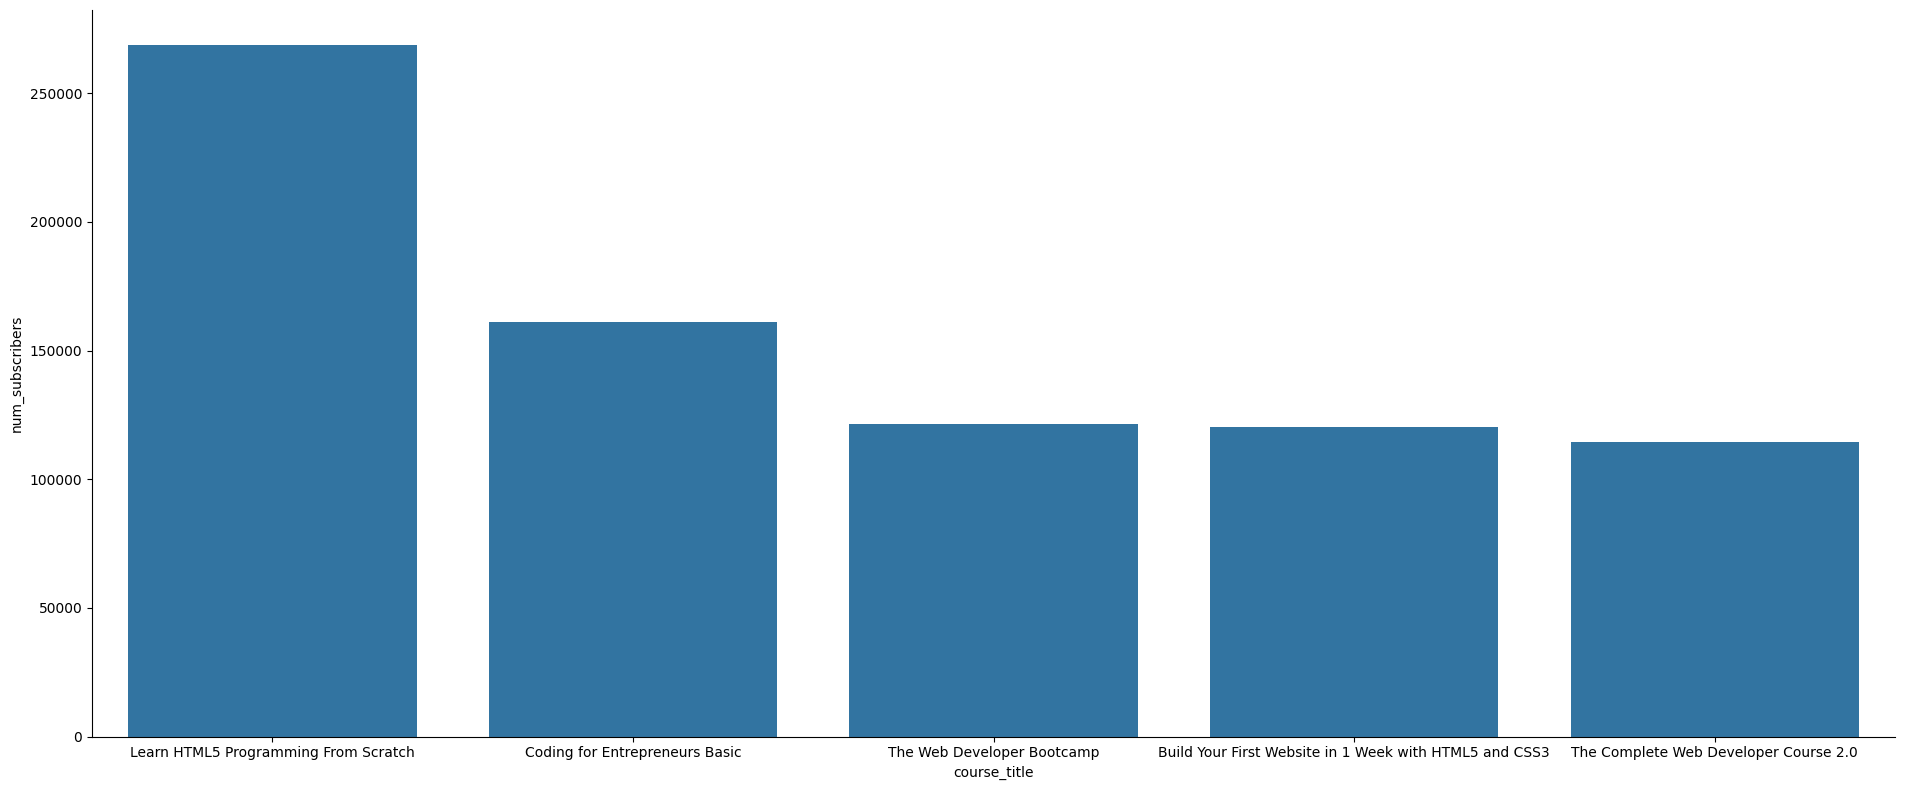

In [76]:
z = df.loc[df.num_subscribers.sort_values(ascending=False).head().index]
sns.catplot(data=z,kind='bar',height=8,aspect=2.4,x='course_title',y='num_subscribers')

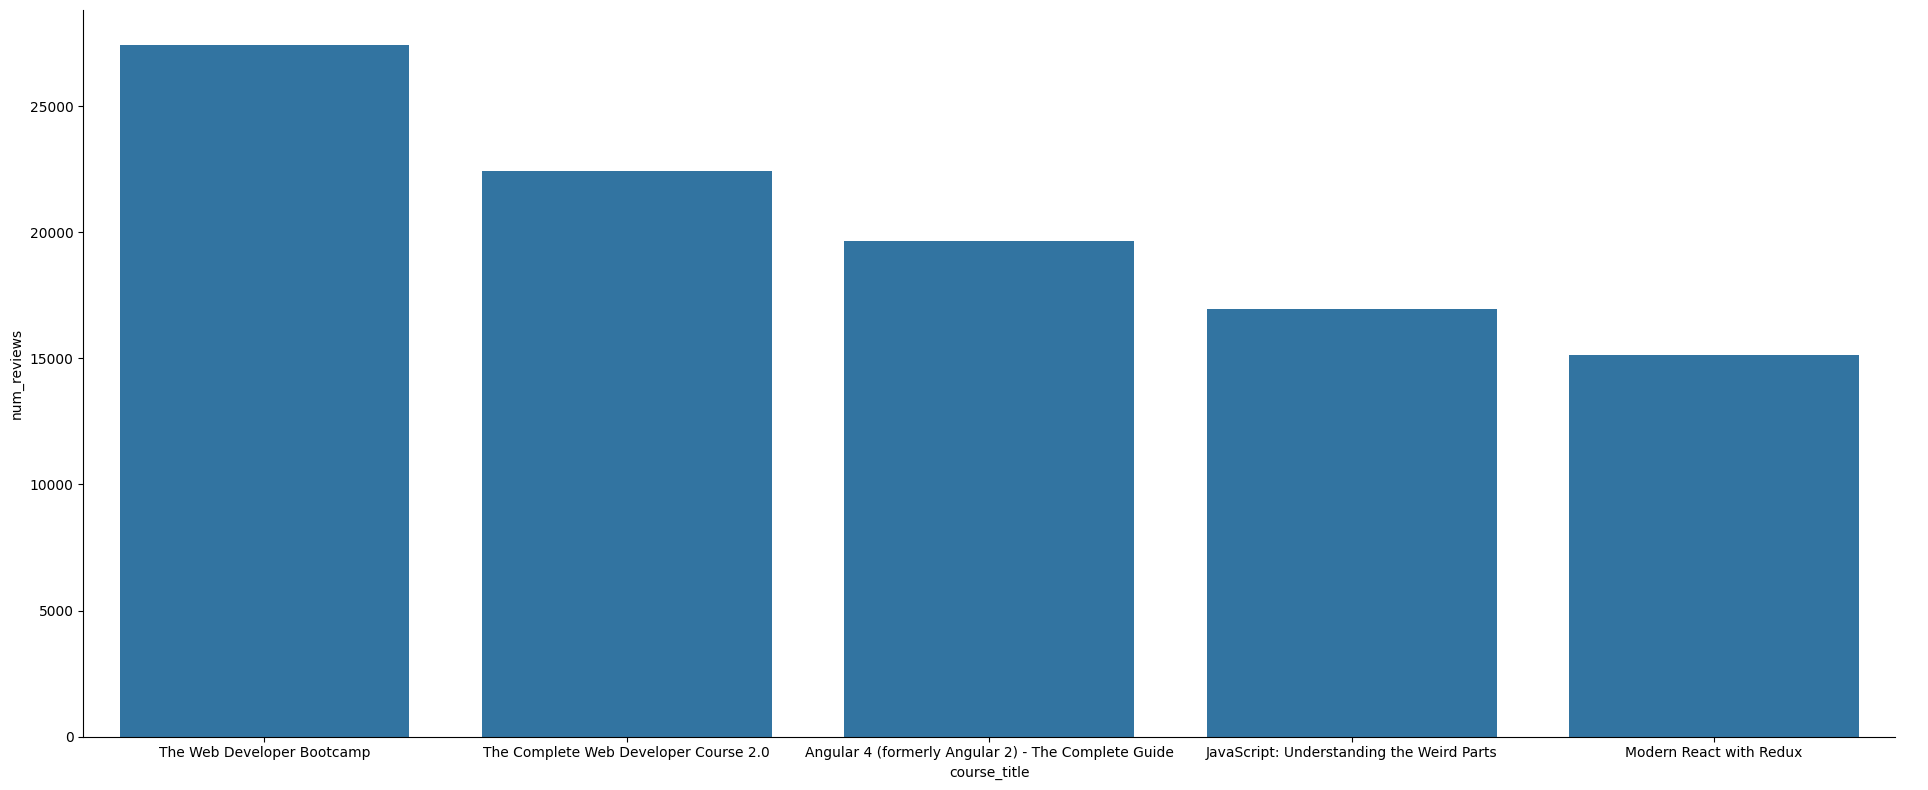

In [77]:
z = df.loc[df.num_reviews.sort_values(ascending=False).head().index]
sns.catplot(data=z,kind='bar',height=8,aspect=2.4,x='course_title',y='num_reviews')

<Axes: xlabel='price_clean', ylabel='count'>

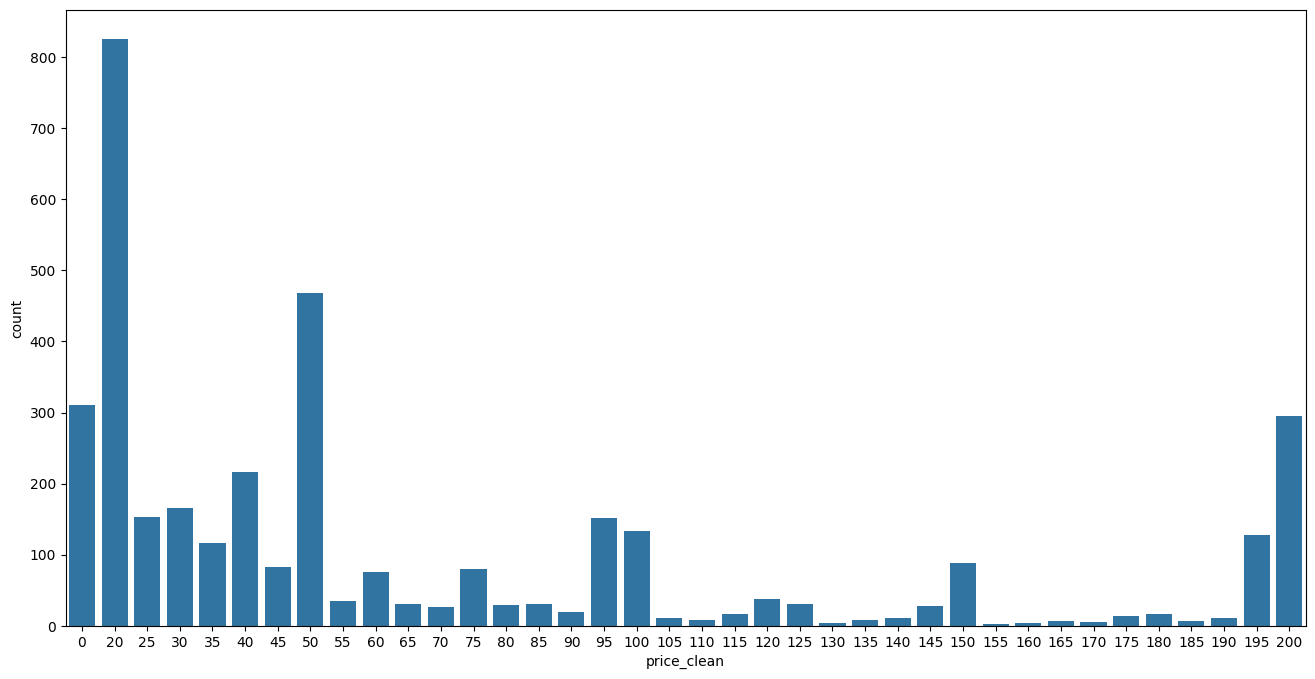

In [78]:
plt.figure(figsize=(16,8))
sns.countplot(data=df,x='price_clean')

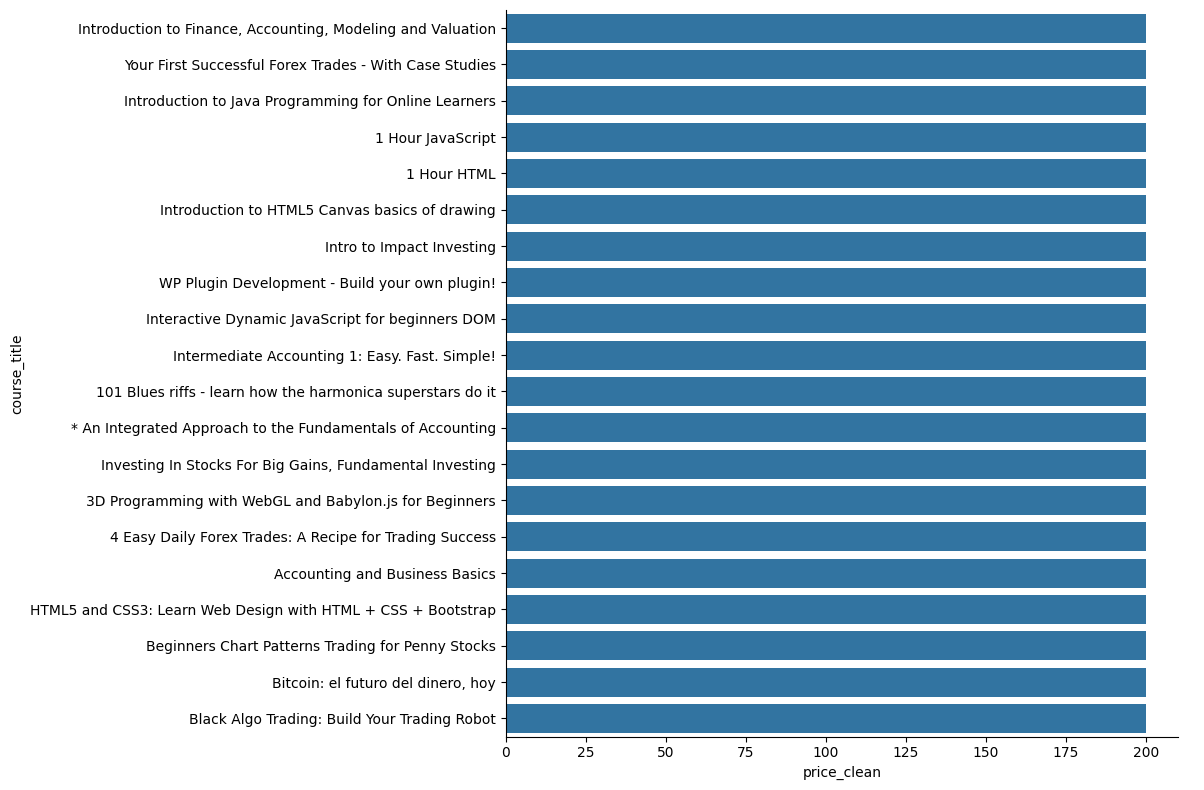

In [79]:
z = df.loc[df.price_clean.sort_values(ascending=False).head(20).index]

sns.catplot(
    data=z,
    kind='bar',
    height=8,
    aspect=1.5,
    y='course_title',
    x='price_clean'   
)